# 02 · EDA de variables, IV y fuga de información

**Población:** decisión 001 (36 meses, 2012–2015). **Todo el análisis se hace solo con entrenamiento (2012–2014):** si miramos 2015 para decidir features, la validación fuera de tiempo deja de ser honesta.

**Objetivo:** decidir qué variables entran al modelo (**decisión 002**).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from credit_lab.poblacion import cargar_poblacion, FUGA, BENCHMARK
from credit_lab.iv import ranking_iv, tabla_woe

pd.set_option("display.float_format", "{:,.3f}".format)
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

df = cargar_poblacion()
df.groupby("muestra")["malo"].agg(prestamos="size", tasa_malo="mean")

,prestamos,tasa_malo
muestra,,
oot,283026,0.149
train,283253,0.132


> **Ojo:** la tasa de malos sube de 13,2% (train) a 14,9% (OOT 2015). El modelo se va a validar en un año **más riesgoso** que el de entrenamiento, justo como pasa en la vida real.

In [2]:
tr = df[df["muestra"].eq("train")].copy()

# Variables derivadas (candidatas)
tr["fico_medio"] = (tr["fico_range_low"] + tr["fico_range_high"]) / 2
tr["antig_credito_meses"] = (
    tr["issue_d"] - pd.to_datetime(tr["earliest_cr_line"], format="%b-%Y")).dt.days / 30.4
tr["monto_ingreso"] = tr["loan_amnt"] / tr["annual_inc"]
tr["cuota_ingreso_mensual"] = tr["installment"] / (tr["annual_inc"] / 12)

no_features = set(FUGA + BENCHMARK + ["id", "loan_status", "issue_d", "anio", "malo",
                                      "muestra", "term", "earliest_cr_line"])
candidatas = [c for c in tr.columns if c not in no_features]
len(candidatas)

39

## 1. Perfil de las variables numéricas: rangos, nulos y valores raros

In [3]:
num = tr[candidatas].select_dtypes("number")
perfil = num.describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]]
perfil["nulos_%"] = num.isna().mean() * 100
perfil

,min,1%,50%,99%,max,nulos_%
loan_amnt,"1,000.000","1,600.000","10,000.000","35,000.000","35,000.000",0.000
funded_amnt,"1,000.000","1,600.000","10,000.000","35,000.000","35,000.000",0.000
installment,30.420,56.761,352.180,"1,217.070","1,409.990",0.000
annual_inc,"3,000.000","18,000.000","60,000.000","246,726.240","7,500,000.000",0.000
dti,0.000,2.080,16.810,34.730,39.990,0.000
delinq_2yrs,0.000,0.000,0.000,4.000,29.000,0.000
fico_range_low,660.000,660.000,685.000,795.000,845.000,0.000
fico_range_high,664.000,664.000,689.000,799.000,850.000,0.000
inq_last_6mths,0.000,0.000,0.000,4.000,7.000,0.000
mths_since_last_delinq,0.000,2.000,31.000,80.000,188.000,51.756


In [4]:
rarezas = {
    "annual_inc > 1 M USD": (tr["annual_inc"] > 1e6).sum(),
    "revol_util > 100%": (tr["revol_util"] > 100).sum(),
    "total_rev_hi_lim = 9.999.999 (¿centinela?)": (tr["total_rev_hi_lim"] == 9_999_999).sum(),
    "home_ownership OTHER/NONE/ANY": tr["home_ownership"].isin(["OTHER", "NONE", "ANY"]).sum(),
    "mths_since_last_delinq nulo (¿nunca en mora?)": tr["mths_since_last_delinq"].isna().sum(),
}
pd.Series(rarezas, name="casos").to_frame()

,casos
annual_inc > 1 M USD,36
revol_util > 100%,806
total_rev_hi_lim = 9.999.999 (¿centinela?),2
home_ownership OTHER/NONE/ANY,76
mths_since_last_delinq nulo (¿nunca en mora?),146600


## 2. Variables redundantes

In [5]:
pares = [("fico_range_low", "fico_range_high"), ("funded_amnt", "loan_amnt"),
         ("installment", "loan_amnt"), ("tot_cur_bal", "avg_cur_bal")]
pd.DataFrame([(a, b, tr[a].corr(tr[b])) for a, b in pares],
             columns=["variable_a", "variable_b", "correlacion"])

,variable_a,variable_b,correlacion
0,fico_range_low,fico_range_high,1.000
1,funded_amnt,loan_amnt,1.000
2,installment,loan_amnt,0.994
3,tot_cur_bal,avg_cur_bal,0.847


## 3. Information Value (IV)

Guía: < 0,02 inútil · 0,02–0,1 débil · 0,1–0,3 media · 0,3–0,5 fuerte · > 0,5 sospechosa (posible fuga).

Se incluye el **benchmark** (`int_rate`, `grade`, `sub_grade`) solo como referencia: es la vara que el retador tiene que superar.

In [6]:
iv = ranking_iv(tr, candidatas + BENCHMARK)
iv["tipo"] = np.where(iv["variable"].isin(BENCHMARK), "benchmark Lending Club", "candidata")
iv

,variable,iv,fuerza,tipo
0,sub_grade,0.320,fuerte,benchmark Lending Club
1,int_rate,0.293,media,benchmark Lending Club
2,grade,0.286,media,benchmark Lending Club
3,fico_range_low,0.133,media,candidata
4,fico_range_high,0.133,media,candidata
5,fico_medio,0.133,media,candidata
6,annual_inc,0.088,débil,candidata
7,total_bc_limit,0.071,débil,candidata
8,avg_cur_bal,0.070,débil,candidata
9,cuota_ingreso_mensual,0.067,débil,candidata


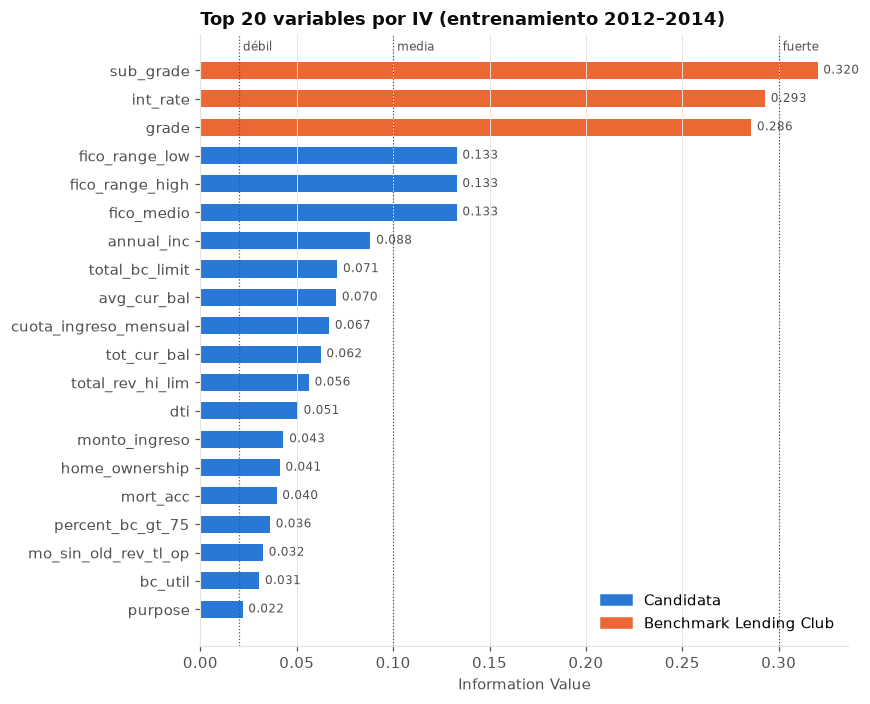

In [7]:
top = iv.head(20).iloc[::-1]
colores = np.where(top["tipo"].eq("candidata"), AZUL, NARANJA)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["variable"], top["iv"], color=colores, height=0.6)
for y, v in enumerate(top["iv"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
for corte, txt in [(0.02, "débil"), (0.1, "media"), (0.3, "fuerte")]:
    ax.axvline(corte, color=TINTA_2, linewidth=0.8, linestyle=":")
    ax.text(corte, len(top) - 0.3, f" {txt}", fontsize=8, color=TINTA_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Information Value")
ax.set_title("Top 20 variables por IV (entrenamiento 2012–2014)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Candidata"), Patch(color=NARANJA, label="Benchmark Lending Club")],
          frameon=False, loc="lower right")
fig.tight_layout()

## 4. Tasa de malos por tramo (top 4 candidatas)

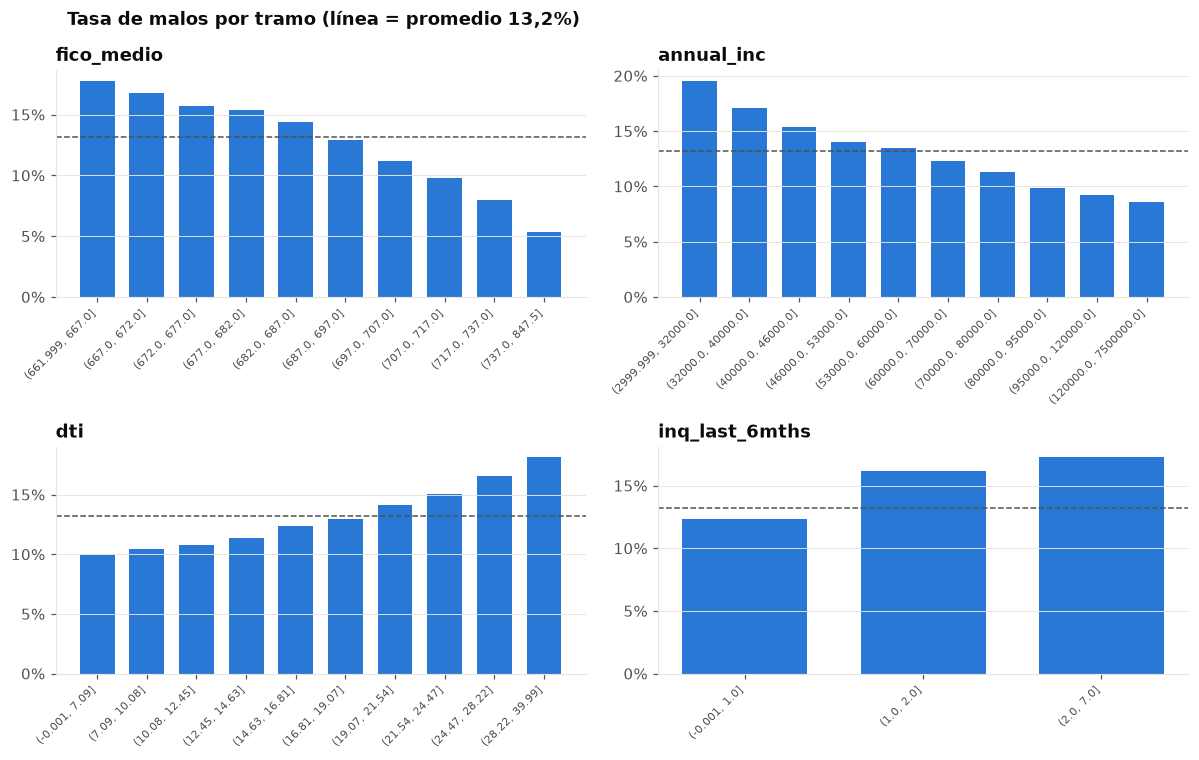

In [8]:
vars_top = ["fico_medio", "annual_inc", "dti", "inq_last_6mths"]
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(ejes.flat, vars_top):
    t = tabla_woe(tr[v], tr["malo"])
    t = t.drop(index="NULO", errors="ignore")
    ax.bar(range(len(t)), t["tasa_malo"], color=AZUL, width=0.7)
    ax.axhline(tr["malo"].mean(), color=TINTA_2, linewidth=1, linestyle="--")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=45, ha="right", fontsize=7)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.grid(axis="x", visible=False)
    ax.set_title(v)
fig.suptitle("Tasa de malos por tramo (línea = promedio 13,2%)", x=0.06, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()

## 5. ¿Por qué la mora previa casi no predice?

`delinq_2yrs`, `pub_rec` y `mths_since_last_delinq` tienen IV ≈ 0, aunque en cualquier buró son de las variables más fuertes. Hipótesis: **sesgo de selección**. Lending Club ya filtró en la aprobación (por ejemplo FICO ≥ 660) y a los que tenían mal historial los rechazó o les cobró más tasa. En la población aprobada esas variables tienen poca variación útil. Por eso existe el *reject inference* (posible sesión extra).

In [9]:
tr["fico_medio"].describe()[["min", "50%", "max"]]

min   662.000
50%   687.000
max   847.500
Name: fico_medio, dtype: float64

## 6. Fuga de información: variables a revisar

| Variable | Riesgo | Propuesta |
|---|---|---|
| `installment` | Se calcula con `loan_amnt` **y `int_rate`**: mete el score de Lending Club por la puerta de atrás | Excluir; recalcular la cuota con una tasa fija |
| `cuota_ingreso_mensual` | Hereda el problema de `installment` | Usar `monto_ingreso` en su lugar |
| `funded_amnt` | Monto que finalmente financiaron los inversionistas (decisión posterior a la solicitud) | Excluir, usar `loan_amnt` |
| `initial_list_status` | Decisión operativa de Lending Club, no del cliente | Excluir |
| `verification_status` | Lending Club pide verificar ingresos a los más riesgosos: refleja su política | Discutir |

---
## ✍️ Conclusiones de Neider

1.
2.
3. 